In [2]:
#pip install scvelo

  Using cached scvelo-0.2.4-py3-none-any.whl (196 kB)
Note: you may need to restart the kernel to use updated packages.


In [39]:
#pip install python-igraph

  Using cached python_igraph-0.9.10-py3-none-any.whl (9.1 kB)
     ---------------------------------------- 2.8/2.8 MB 9.4 MB/s eta 0:00:00
  Using cached texttable-1.6.4-py2.py3-none-any.whl (10 kB)
Note: you may need to restart the kernel to use updated packages.


In [42]:
#pip install louvain

     -------------------------------------- 94.4/94.4 KB 905.4 kB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [44]:
#pip install scanpy[leiden]


     ------------------------------------ 104.9/104.9 KB 860.8 kB/s eta 0:00:00


In [1]:
import pandas as pd
import scanpy as sc
import numpy as np
from numpy import linalg as la
from scipy.sparse import issparse
import loompy
import anndata
import scvelo as scv
scv.logging.print_version()

Running scvelo 0.2.4 (python 3.8.13) on 2022-05-12 09:50.


In [2]:
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import display, HTML

import dynamo as dyn
dyn.configuration.set_figure_params('dynamo', background='white')
dyn.get_all_dependencies_version()

|-----> setting visualization default mode in dynamo. Your customized matplotlib settings might be overritten.


package,python-igraph,numdifftools,seaborn,numba,dynamo-release,cvxopt,numpy,networkx,pre-commit,colorcet,loompy,openpyxl,matplotlib,get-version,setuptools,umap-learn,pynndescent,statsmodels,scikit-learn,pandas,scipy,tqdm
version,0.9.10,0.9.40,0.11.2,0.55.1,1.1.0,1.3.0,1.21.6,2.8,2.18.1,3.0.0,3.0.7,3.0.9,3.4.3,3.5.4,61.2.0,0.5.2,0.5.5,0.13.1,1.0.2,1.3.5,1.7.3,4.62.3


In [3]:
sc.settings.verbosity = 3             # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.logging.print_header()
sc.settings.set_figure_params(dpi=80, facecolor='white')

scanpy==1.8.2 anndata==0.7.5 umap==0.5.2 numpy==1.21.5 scipy==1.7.3 pandas==1.3.5 scikit-learn==1.0.2 statsmodels==0.13.1 python-igraph==0.9.10 louvain==0.7.1 pynndescent==0.5.5


In [5]:
import os
os.chdir('C:/Users/KKo1/OneDrive - mdanderson.org/13. KyungPil Ko/Experiment_results/scRNA-seq/2020_nature_comm/Dynamo/Integrated')
adata_11 = dyn.read('normal-CIS_integrated_subcluster_dynamo.h5ad')

AnnDataReadError: Above error raised while reading key '/layers/M_u' of type <class 'h5py._hl.group.Group'> from /.

In [ ]:
adata_NC = adata_11[adata_11.obs['batch'].isin(['Normal','CIS'])]

In [ ]:
adata_NC

In [ ]:
dyn.pl.streamline_plot(adata_NC, color=['louvain'], basis='umap', show_legend='on data', show_arrowed_spines=True, pointsize=0.3, theme='fire')

In [ ]:
del adata_NC.uns['batch_colors']

In [ ]:
adata_NC.write('Normal_and_CIS_from_integrated.h5ad', compression='gzip')

In [ ]:
import os
os.chdir('C:/Users/KKo1/OneDrive - mdanderson.org/13. KyungPil Ko/Experiment_results/scRNA-seq/2020_nature_comm/Dynamo/Integrated')

adata_NC = sc.read('Normal_and_CIS_from_integrated.h5ad')

In [ ]:
adata = adata_NC

In [ ]:
adata.var_names_make_unique()
adata # this is unnecessary if using `var_names='gene_ids'` in `sc.read_10x_mtx`

In [ ]:
# mitochondrial genes
adata.var['mt'] = adata.var_names.str.startswith('mt-') 
# ribosomal genes
adata.var['ribo'] = adata.var_names.str.startswith(("Rps","Rpl"))
# hemoglobin genes.
adata.var['hb'] = adata.var_names.str.contains(("^hb[^(P)]"))

adata.var

In [ ]:
sc.pp.calculate_qc_metrics(adata, qc_vars=['mt','ribo','hb'], percent_top=None, log1p=False, inplace=True)

In [ ]:
sc.pl.scatter(adata, x='total_counts', y='pct_counts_mt', color="batch")

In [ ]:
sc.pl.scatter(adata, x='total_counts', y='pct_counts_ribo', color="batch")

In [ ]:
mito_genes = adata.var_names.str.startswith('mt-')
# for each cell compute fraction of counts in mito genes vs. all genes
# the `.A1` is only necessary as X is sparse (to transform to a dense array after summing)
adata.obs['percent_mt2'] = np.sum(
    adata[:, mito_genes].X, axis=1).A1 / np.sum(adata.X, axis=1).A1
# add the total counts per cell as observations-annotation to adata
adata.obs['n_counts'] = adata.X.sum(axis=1).A1

In [ ]:
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)

print(adata.n_obs, adata.n_vars)

In [ ]:
sc.pl.highest_expr_genes(adata, n_top=20)

In [ ]:
# filter for percent mito
adata = adata[adata.obs['pct_counts_mt'] < 10, :]

# filter for percent ribo > 0.05
adata = adata[adata.obs['pct_counts_ribo'] > 5, :]

print("Remaining cells %d"%adata.n_obs)

In [ ]:
adata

In [ ]:
adata_New8 = adata[adata.obs['louvain'].isin(['New_8'])]
adata_New8

In [ ]:
adata_New4 = adata[adata.obs['louvain'].isin(['New_4'])]
adata_New4

In [ ]:
adata_Epi2 = adata[adata.obs['louvain'].isin(['Epi_2'])]
adata_Epi2

In [ ]:
adata_New6 = adata[adata.obs['louvain'].isin(['New_6'])]
adata_New6

In [ ]:
adata_New7 = adata[adata.obs['louvain'].isin(['New_7'])]
adata_New7

In [ ]:
sc.pl.umap(adata_New8, color=['batch'], save='umap_New8_Normal_CIS.pdf')

In [ ]:
sc.pl.umap(adata_New4, color=['batch'], save='umap_New4_Normal_CIS.pdf')

In [6]:
sc.pl.umap(adata_Epi2, color=['batch'], save='umap_Epi2_Normal_CIS.pdf')

NameError: name 'adata_Epi2' is not defined

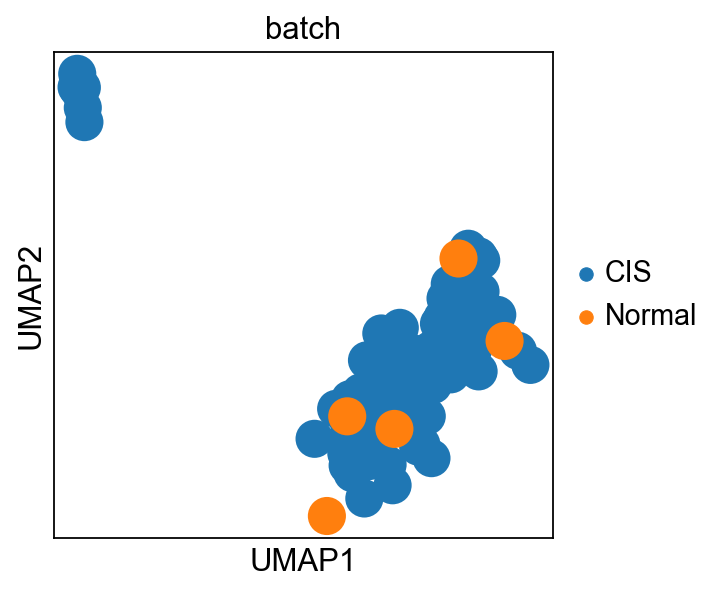

In [59]:
sc.pl.umap(adata_New6, color=['batch'])

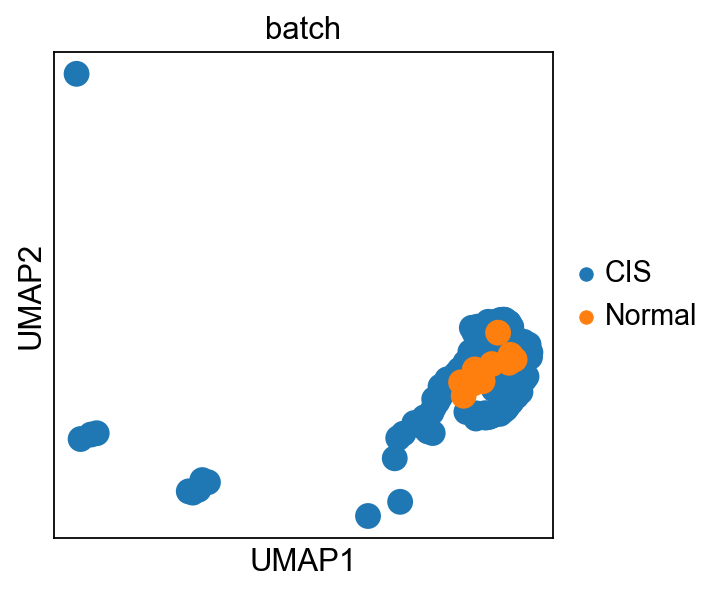

In [74]:
sc.pl.umap(adata_New7, color=['batch'])

ranking genes
    finished (0:00:01)


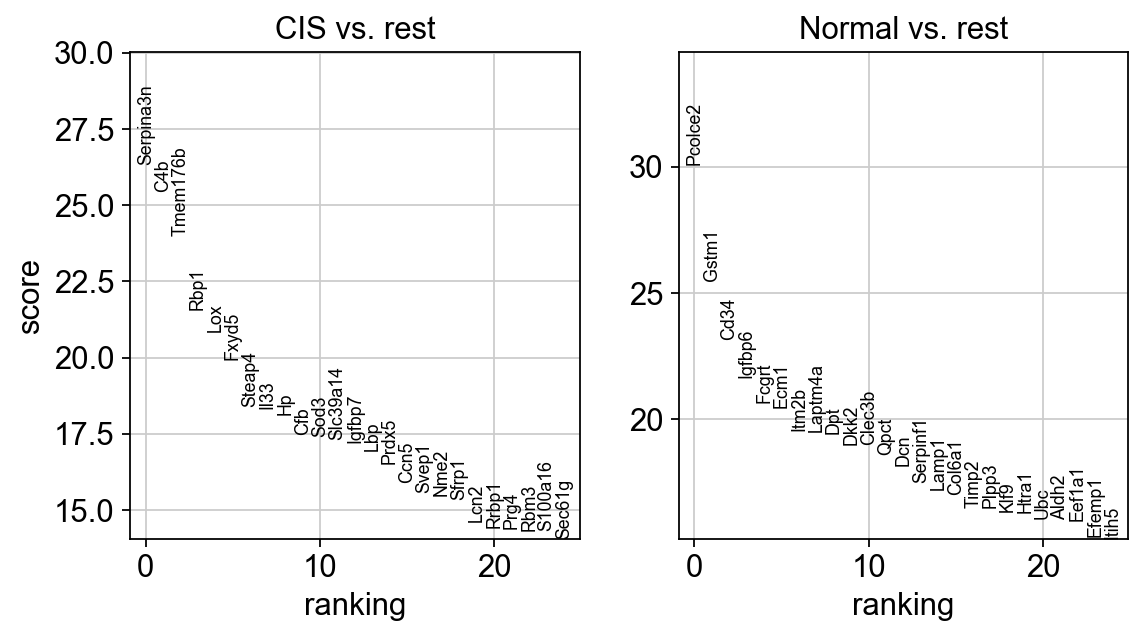

In [60]:
sc.tl.rank_genes_groups(adata_New8, 'batch', method='t-test')
sc.pl.rank_genes_groups(adata_New8, n_genes=25, sharey=False)

In [61]:
sc.settings.verbosity = 2  # reduce the verbosity

ranking genes
    finished (0:00:00)


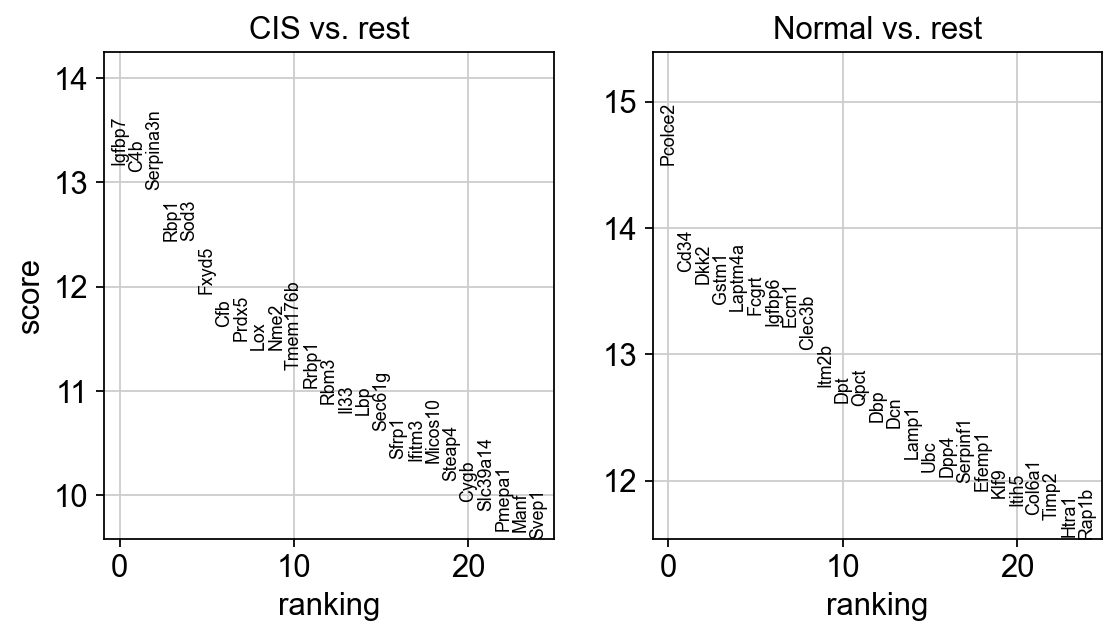

In [62]:
sc.tl.rank_genes_groups(adata_New8, 'batch', method='wilcoxon')
sc.pl.rank_genes_groups(adata_New8, n_genes=25, sharey=False)

In [63]:
df=pd.DataFrame(adata_New8.uns['rank_genes_groups']['names'])
df.to_csv("/Users/KKo1/OneDrive - mdanderson.org/13. KyungPil Ko/Experiment_results/scRNA-seq/2020_nature_comm/Dynamo/Integrated/normalvsCIS_from_integrated/New8_markergene.csv",
                 sep=',', na_rep='', float_format=None, columns=None, header=True, 
                 index=True, index_label=None, mode='w', encoding=None, compression='infer', 
                 quoting=None, quotechar='"', line_terminator=None, chunksize=None, date_format=None)

ranking genes
    finished (0:00:02)


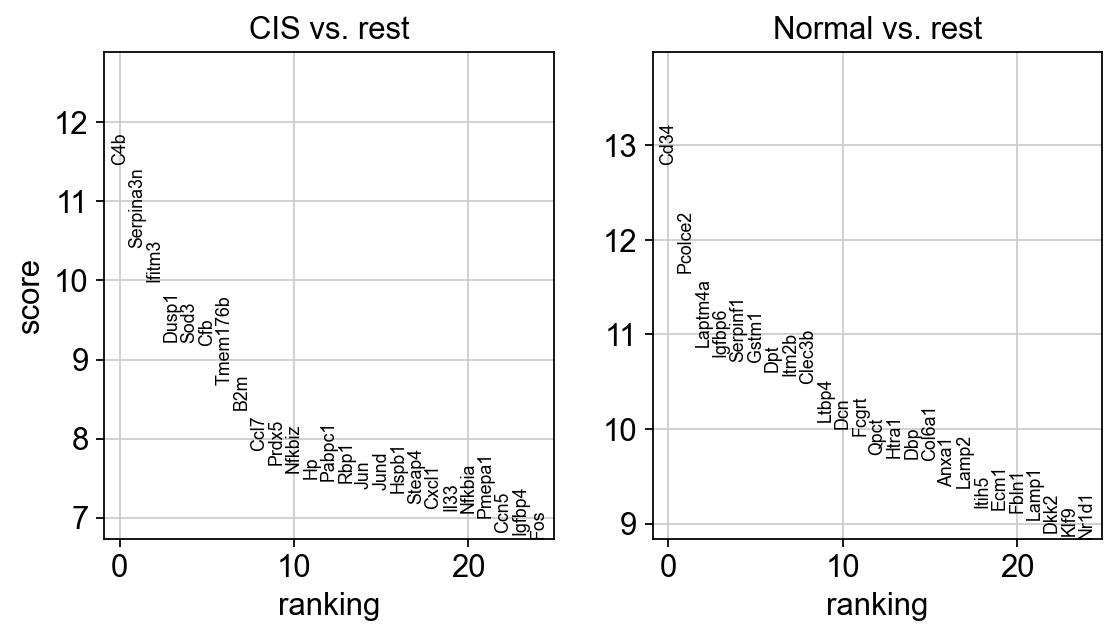

In [64]:
sc.tl.rank_genes_groups(adata_New4, 'batch', method='wilcoxon')
sc.pl.rank_genes_groups(adata_New4, n_genes=25, sharey=False)

In [65]:
df=pd.DataFrame(adata_New4.uns['rank_genes_groups']['names'])
df.to_csv("/Users/KKo1/OneDrive - mdanderson.org/13. KyungPil Ko/Experiment_results/scRNA-seq/2020_nature_comm/Dynamo/Integrated/normalvsCIS_from_integrated/New4_markergene.csv",
                 sep=',', na_rep='', float_format=None, columns=None, header=True, 
                 index=True, index_label=None, mode='w', encoding=None, compression='infer', 
                 quoting=None, quotechar='"', line_terminator=None, chunksize=None, date_format=None)

ranking genes
    finished (0:00:00)


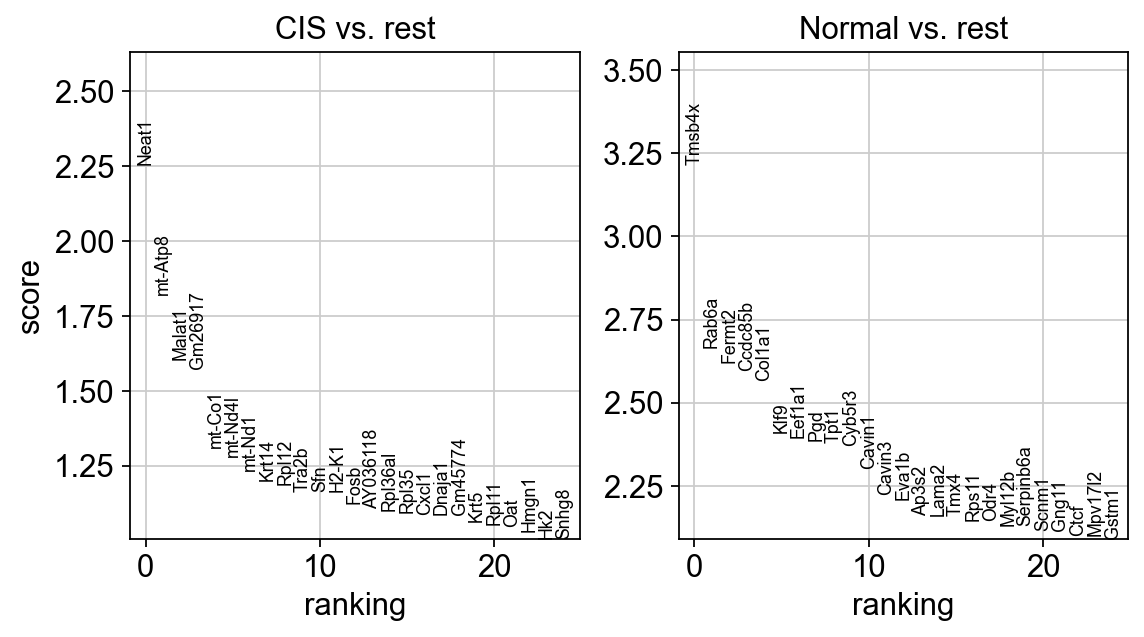

In [66]:
sc.tl.rank_genes_groups(adata_New6, 'batch', method='wilcoxon')
sc.pl.rank_genes_groups(adata_New6, n_genes=25, sharey=False)

In [67]:
df=pd.DataFrame(adata_New6.uns['rank_genes_groups']['names'])
df.to_csv("/Users/KKo1/OneDrive - mdanderson.org/13. KyungPil Ko/Experiment_results/scRNA-seq/2020_nature_comm/Dynamo/Integrated/normalvsCIS_from_integrated/New6_markergene.csv",
                 sep=',', na_rep='', float_format=None, columns=None, header=True, 
                 index=True, index_label=None, mode='w', encoding=None, compression='infer', 
                 quoting=None, quotechar='"', line_terminator=None, chunksize=None, date_format=None)

ranking genes
    finished (0:00:00)


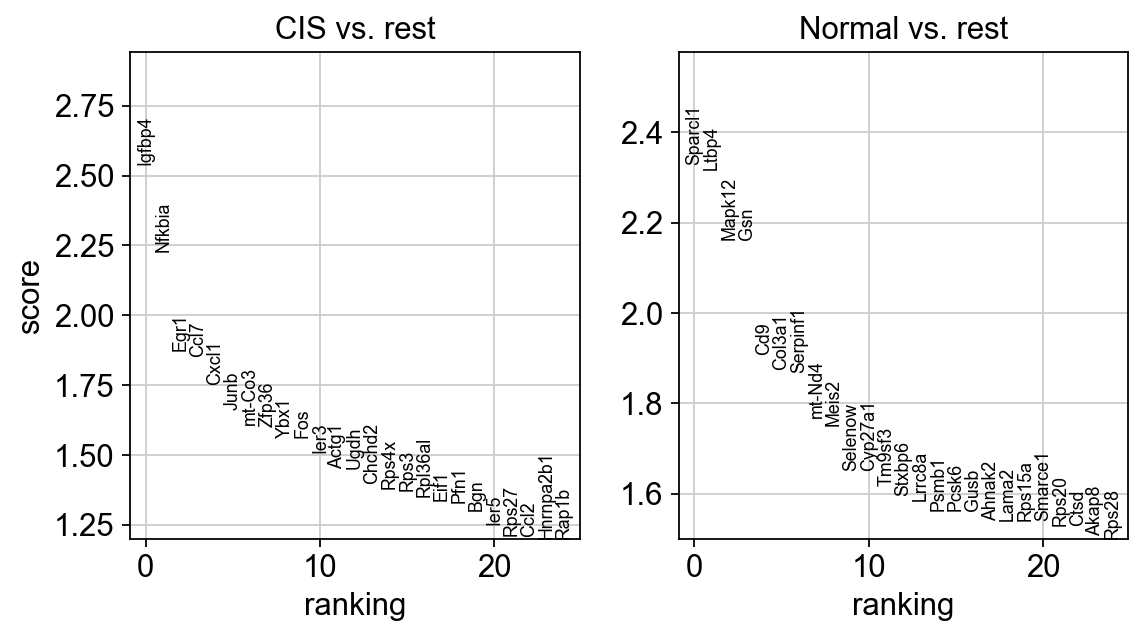

In [68]:
sc.tl.rank_genes_groups(adata_Epi2, 'batch', method='wilcoxon')
sc.pl.rank_genes_groups(adata_Epi2, n_genes=25, sharey=False)

In [69]:
df=pd.DataFrame(adata_Epi2.uns['rank_genes_groups']['names'])
df.to_csv("/Users/KKo1/OneDrive - mdanderson.org/13. KyungPil Ko/Experiment_results/scRNA-seq/2020_nature_comm/Dynamo/Integrated/normalvsCIS_from_integrated/Epi2_markergene.csv",
                 sep=',', na_rep='', float_format=None, columns=None, header=True, 
                 index=True, index_label=None, mode='w', encoding=None, compression='infer', 
                 quoting=None, quotechar='"', line_terminator=None, chunksize=None, date_format=None)

ranking genes
    finished (0:00:01)


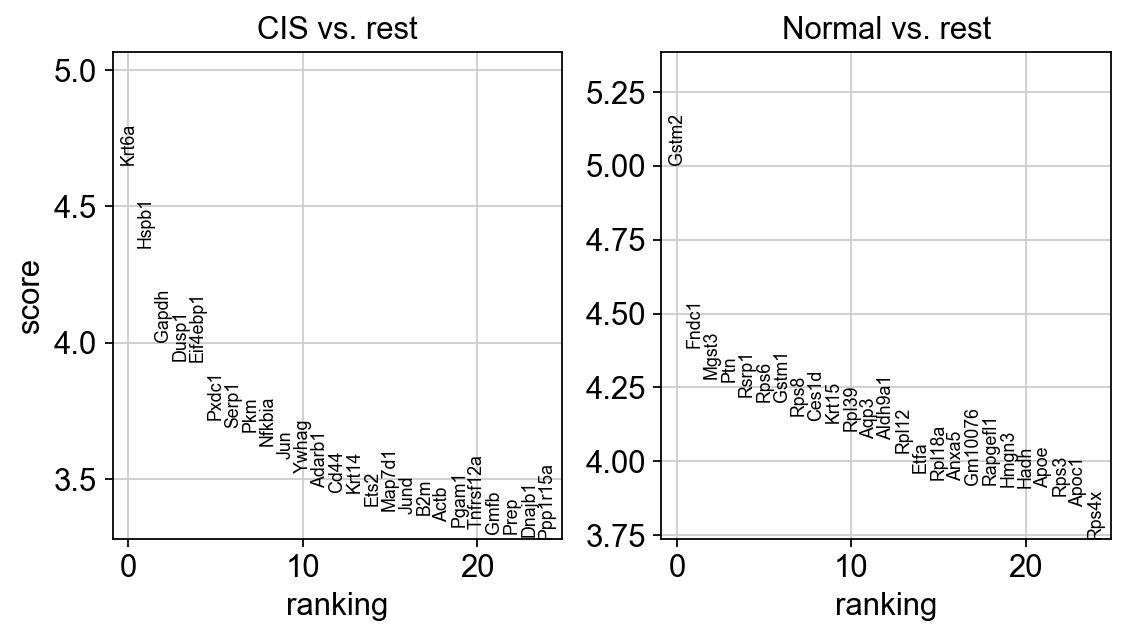

In [72]:
sc.tl.rank_genes_groups(adata_New7, 'batch', method='wilcoxon')
sc.pl.rank_genes_groups(adata_New7, n_genes=25, sharey=False)

In [73]:
df=pd.DataFrame(adata_New7.uns['rank_genes_groups']['names'])
df.to_csv("/Users/KKo1/OneDrive - mdanderson.org/13. KyungPil Ko/Experiment_results/scRNA-seq/2020_nature_comm/Dynamo/Integrated/normalvsCIS_from_integrated/New7_markergene.csv",
                 sep=',', na_rep='', float_format=None, columns=None, header=True, 
                 index=True, index_label=None, mode='w', encoding=None, compression='infer', 
                 quoting=None, quotechar='"', line_terminator=None, chunksize=None, date_format=None)

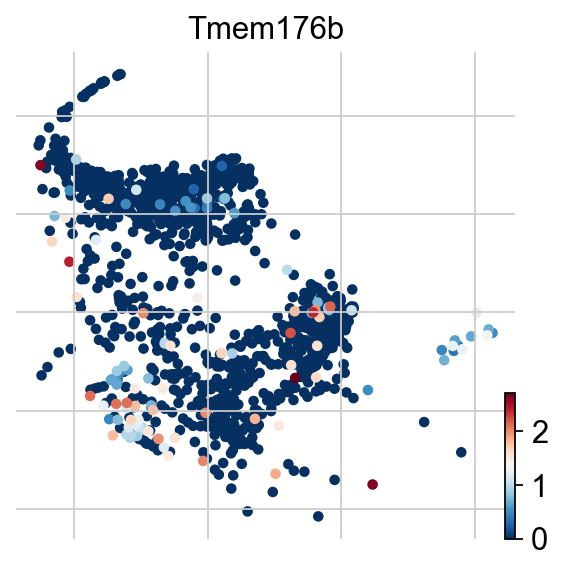

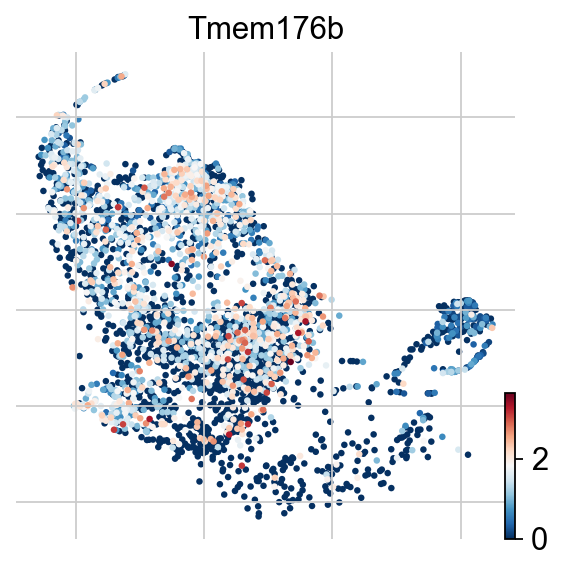

In [16]:
scv.pl.scatter(adata[adata.obs["batch"] == "Normal"], color= ['Tmem176b'], basis='umap')
scv.pl.scatter(adata[adata.obs["batch"] == "CIS"], color= ['Tmem176b'], basis='umap')

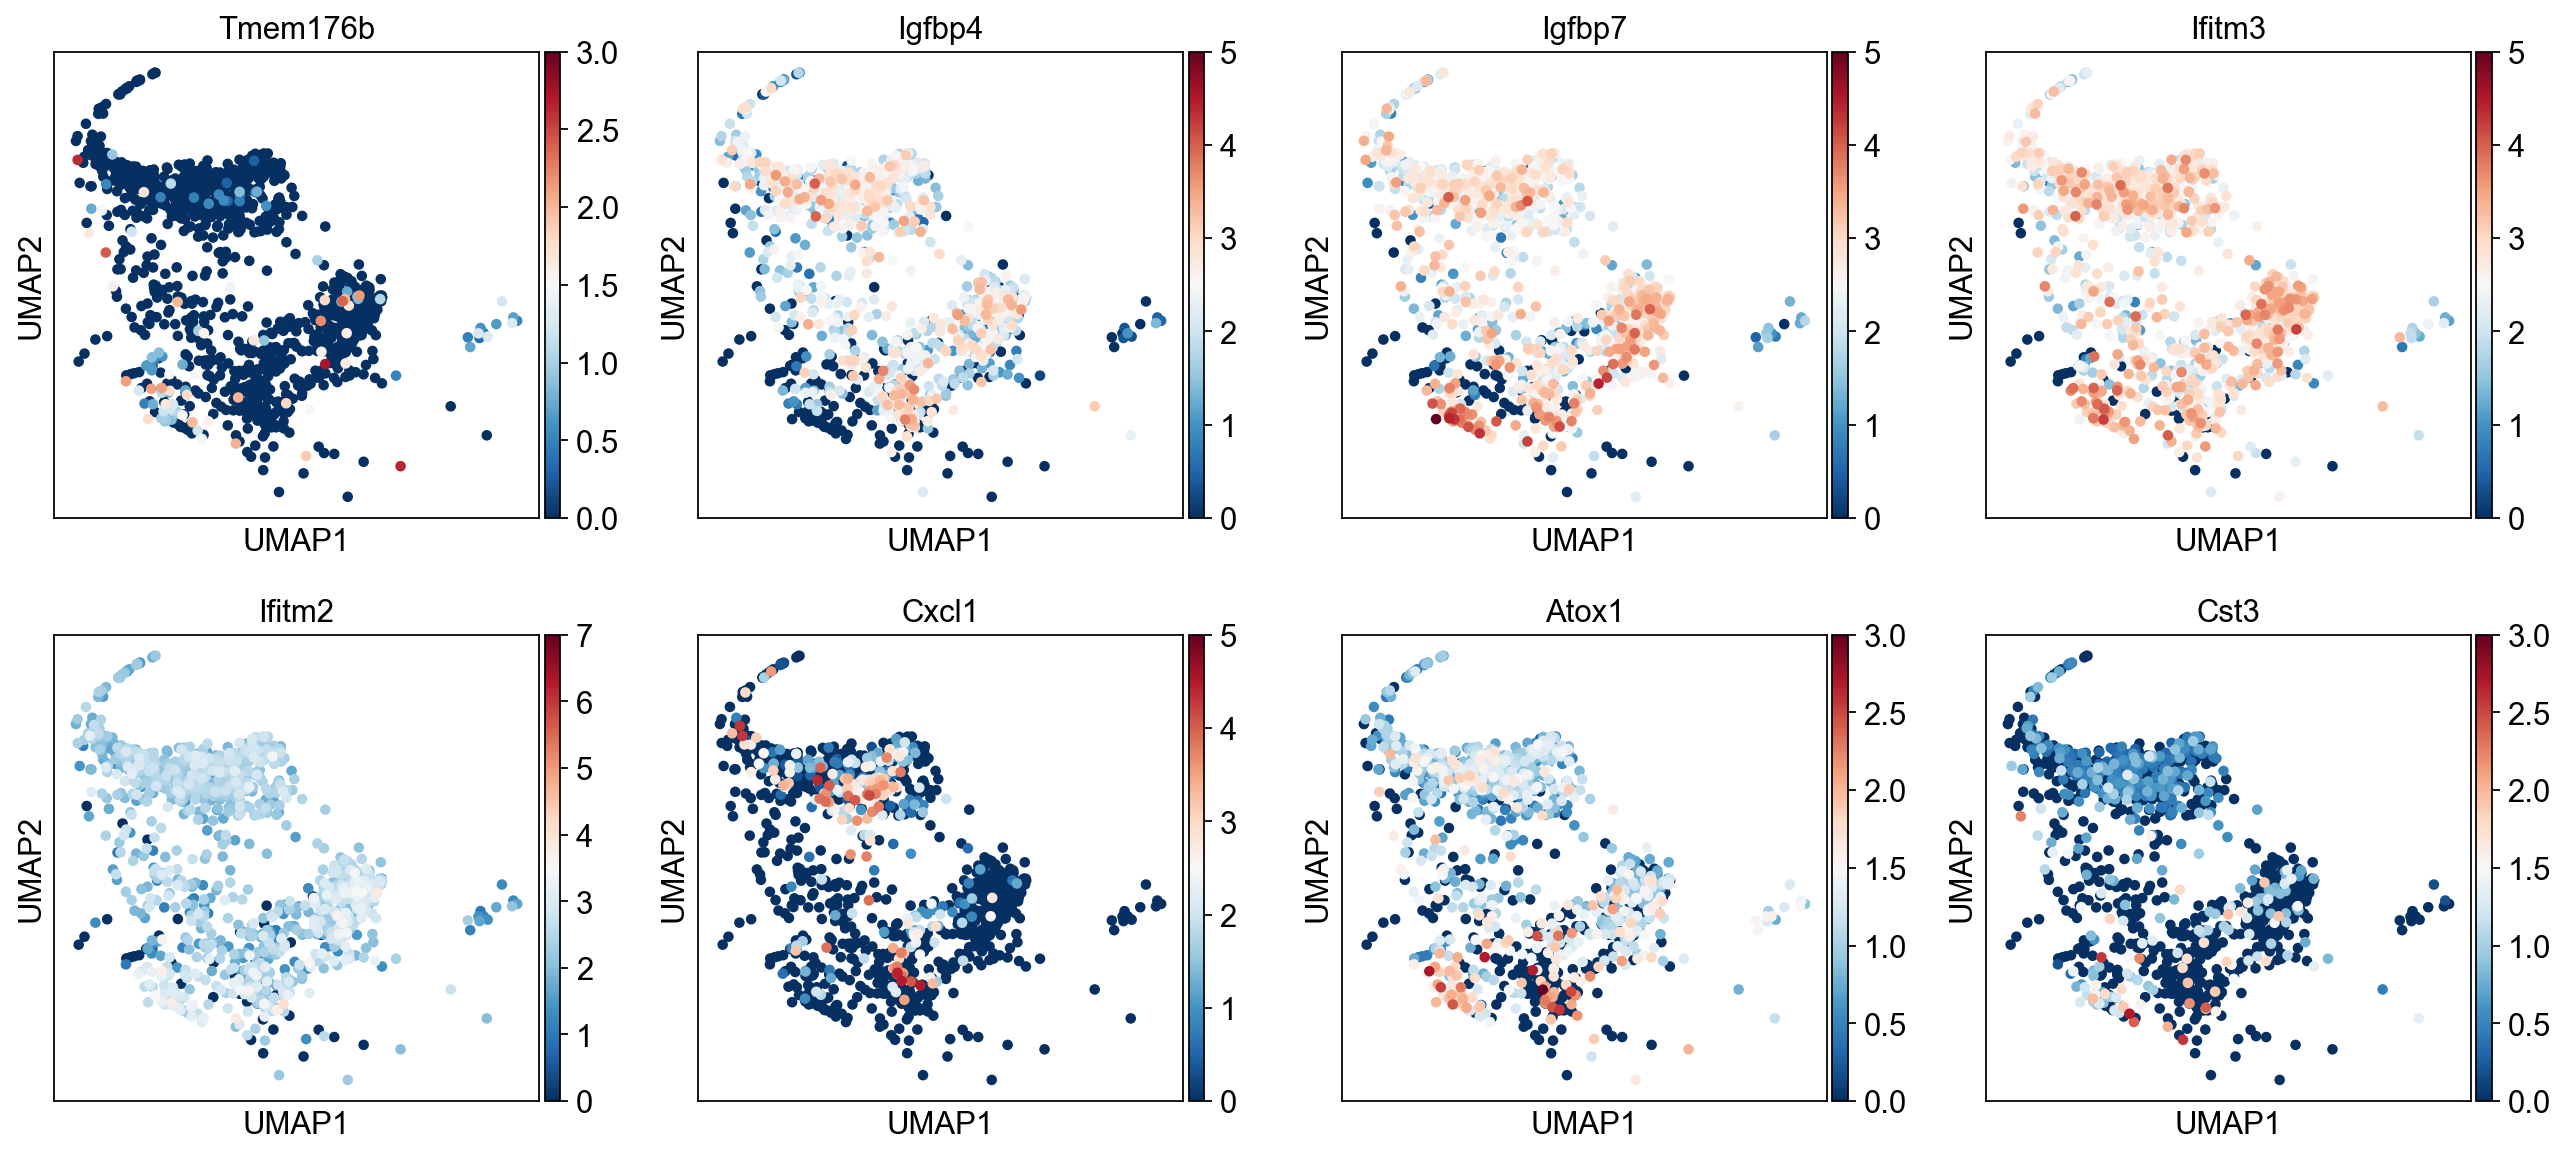

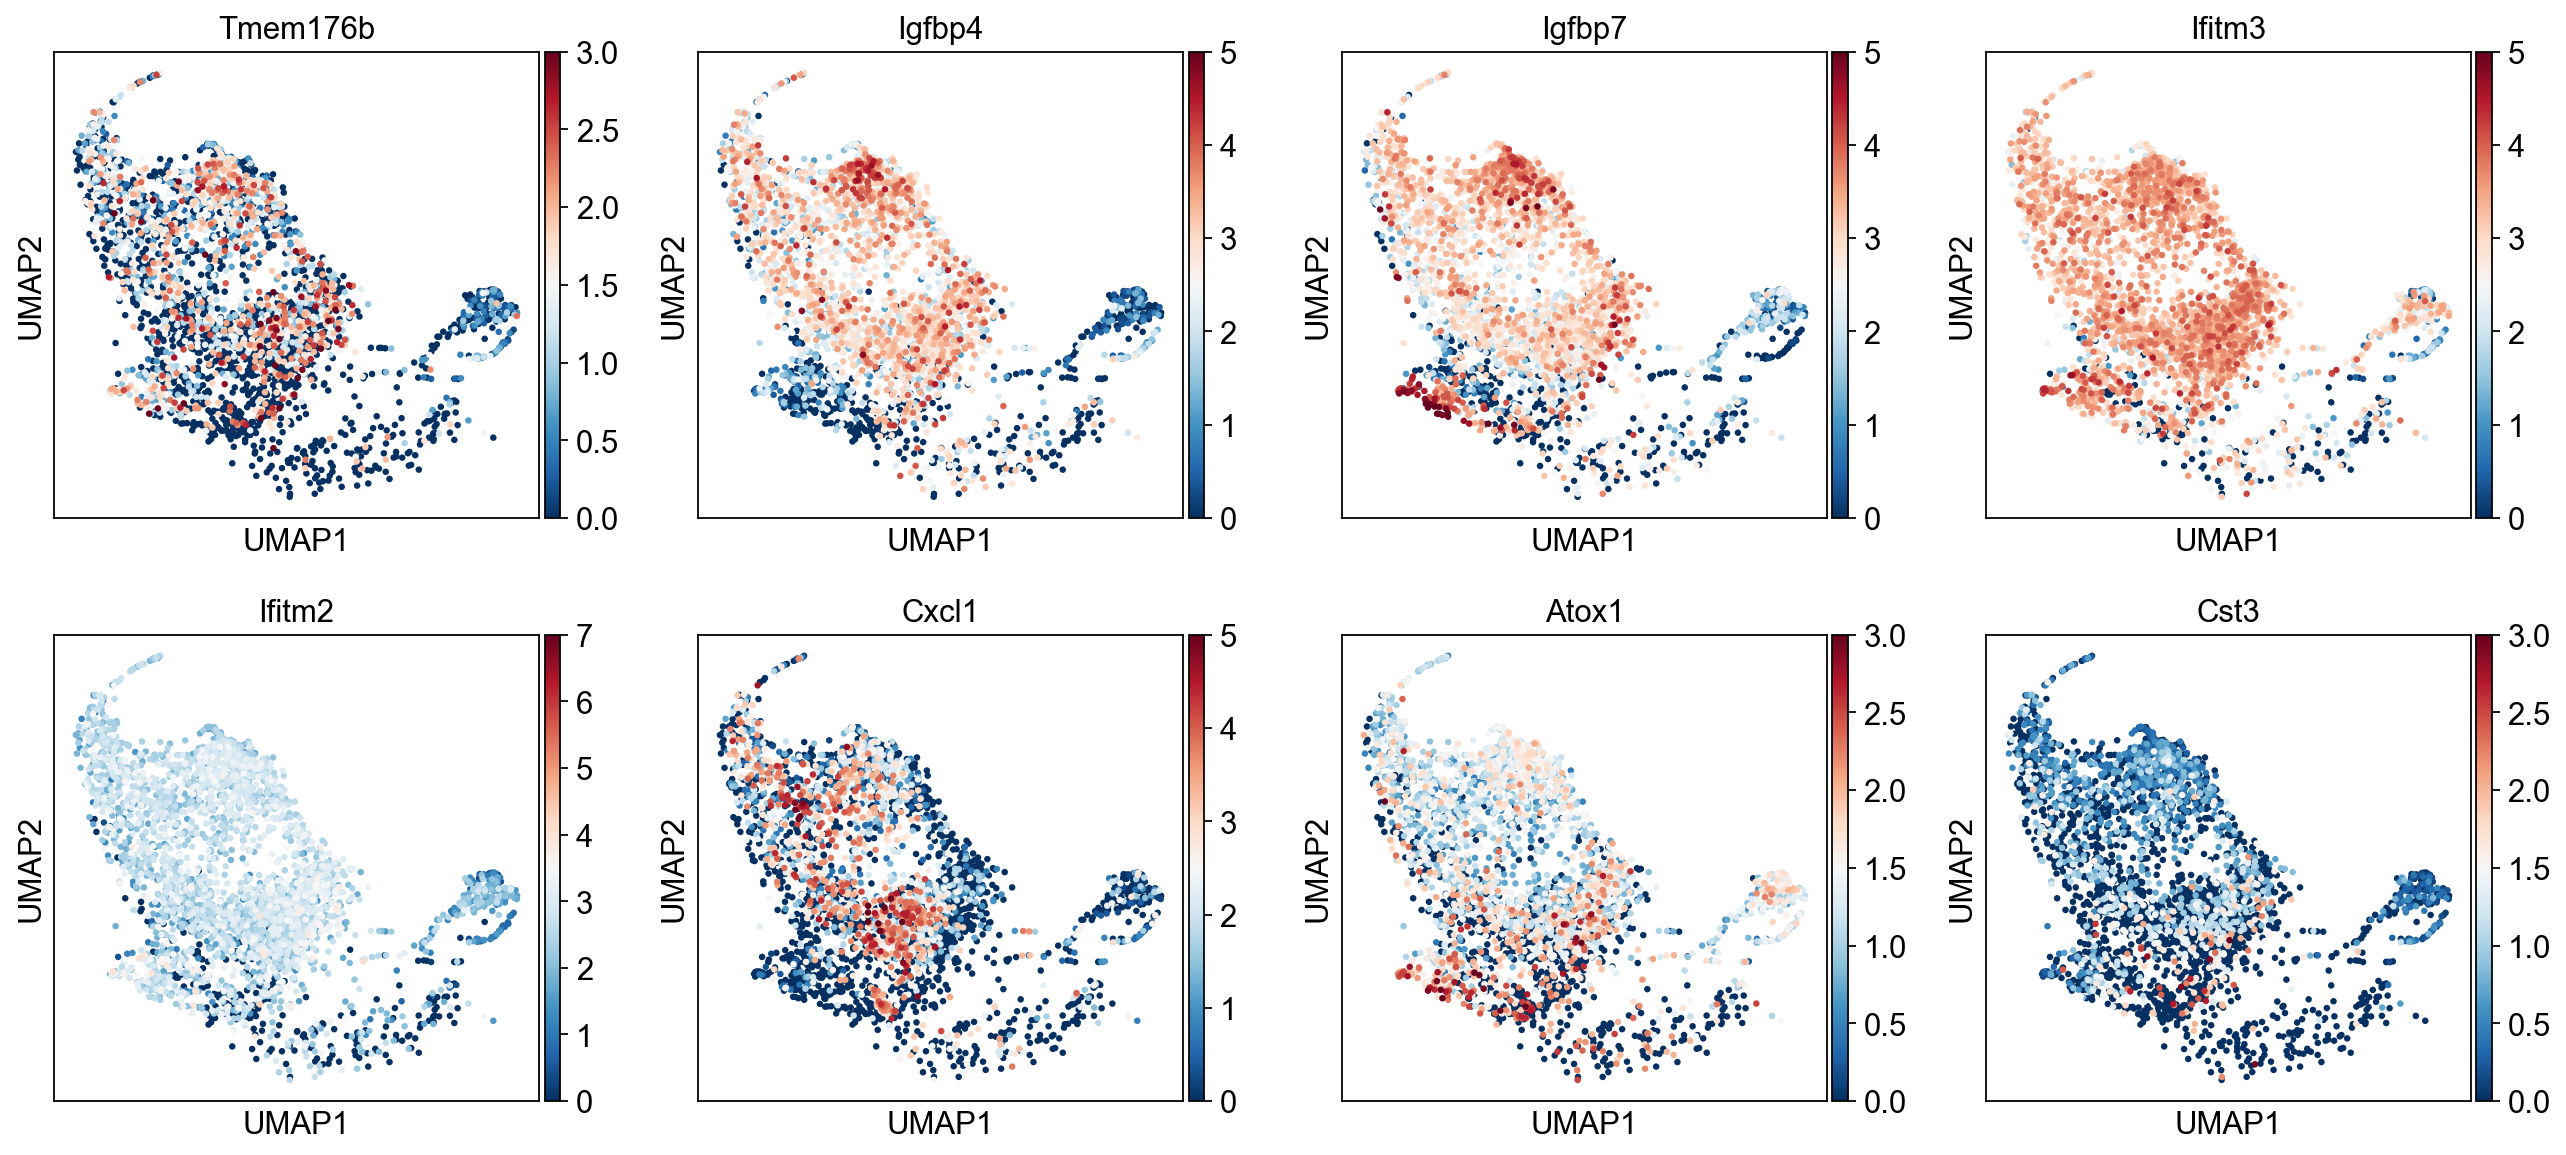

In [19]:
sc.pl.umap(adata[adata.obs["batch"] == "Normal"], color= ['Tmem176b','Igfbp4','Igfbp7','Ifitm3','Ifitm2','Cxcl1','Atox1','Cst3'], vmax=[3,5,5,5,7,5,3,3], save='Normal_biomarkers.pdf')
sc.pl.umap(adata[adata.obs["batch"] == "CIS"], color= ['Tmem176b','Igfbp4','Igfbp7','Ifitm3','Ifitm2','Cxcl1','Atox1','Cst3'], vmax=[3,5,5,5,7,5,3,3], save='CIS_biomarkers.pdf')

In [ ]:
#regulon from 4NQO data result
sc.pl.umap(adata[adata.obs["batch"] == "Normal"], color= ['Mki67','Prrx2','Cebpb','Zbtb7b','Snai2','Tfap2a','Tfap2c','Trp63','Snai3'], vmax=[4,1.5,5,3,3,3,3,3.5,1], save='Normal_TFs_umap.pdf')
sc.pl.umap(adata[adata.obs["batch"] == "CIS"], color= ['Mki67','Prrx2','Cebpb','Zbtb7b','Snai2','Tfap2a','Tfap2c','Trp63','Snai3'], vmax=[4,1.5,5,3,3,3,3,3.5,1], save='CIS_TFs_umap.pdf')

In [ ]:
scv.pp.filter_genes(adata, min_shared_counts=20)
scv.pp.normalize_per_cell(adata)
scv.pp.filter_genes_dispersion(adata, n_top_genes=2000)
scv.pp.log1p(adata)
adata